In [3]:

import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import matplotlib.pyplot as plt

df= pd.read_csv('dataset_transactions_fraude_5000.csv')
df.head()

,transaction_id,amount,transaction_hour,merchant_category,customer_age,customer_country,payment_method,is_international,customer_transaction_count,account_age_days,is_fraud
0,TX100000,124800,21,restaurant,31.0,Nigeria,mobile_money,0,6,839,0
1,TX100001,20500,17,supermarket,38.0,Côte d'Ivoire,bank_transfer,0,5,365,0
2,TX100002,10700,9,fashion,67.0,France,card,0,10,922,0
3,TX100003,134700,1,travel,23.0,Sénégal,mobile_money,1,11,1276,0
4,TX100004,111200,3,supermarket,24.0,Côte d'Ivoire,mobile_money,0,16,2206,0


In [12]:
df.shape

(5000, 11)

In [16]:
df.dtypes

transaction_id                 object
amount                          int64
transaction_hour                int64
merchant_category              object
customer_age                  float64
customer_country               object
payment_method                 object
is_international                int64
customer_transaction_count      int64
account_age_days                int64
is_fraud                        int64
dtype: object

In [11]:
missing = df.isnull().mean()*100
missing[missing > 0].sort_values(ascending= False)  

merchant_category    1.5
customer_age         1.5
payment_method       1.5
dtype: float64

In [15]:
#remplacement des valeur manquante dans nos var qui en possède
# 1. Remplacement pour les variables textuelles
df['merchant_category'] = df['merchant_category'].fillna(df['merchant_category'].mode()[0])
df['payment_method'] = df['payment_method'].fillna(df['payment_method'].mode()[0])

# 2. Remplacement pour la variable numérique (par la médiane)
mediane_age = df['customer_age'].median()
df['customer_age'] = df['customer_age'].fillna(mediane_age)

In [16]:
#det des outliers
q1= df[["amount","customer_transaction_count","account_age_days"]].quantile(0.25)
q3=df[["amount","customer_transaction_count","account_age_days"]].quantile(0.75)
iqr= q3 - q1  #determination de l'écart interquartiles
borne_inf= q1 - 1.5 * iqr
borne_sup= q3 + 1.5 * iqr

#enregistrement des outliers
amount_outliers=  df[(df['amount'] < borne_inf['amount']) | (df['amount'] > borne_sup['amount'])]["amount"]

customer_transaction_outliers= df[(df['customer_transaction_count'] < borne_inf['customer_transaction_count'])\
| (df['customer_transaction_count'] > borne_sup['customer_transaction_count'])]["customer_transaction_count"]

account_age_outliers=  df[(df['account_age_days'] < borne_inf['account_age_days']) | (df['account_age_days'] > borne_sup['account_age_days'])]\
["account_age_days"]

In [4]:
df.head()

,transaction_id,amount,transaction_hour,merchant_category,customer_age,customer_country,payment_method,is_international,customer_transaction_count,account_age_days,is_fraud
0,TX100000,124800,21,restaurant,31.0,Nigeria,mobile_money,0,6,839,0
1,TX100001,20500,17,supermarket,38.0,Côte d'Ivoire,bank_transfer,0,5,365,0
2,TX100002,10700,9,fashion,67.0,France,card,0,10,922,0
3,TX100003,134700,1,travel,23.0,Sénégal,mobile_money,1,11,1276,0
4,TX100004,111200,3,supermarket,24.0,Côte d'Ivoire,mobile_money,0,16,2206,0


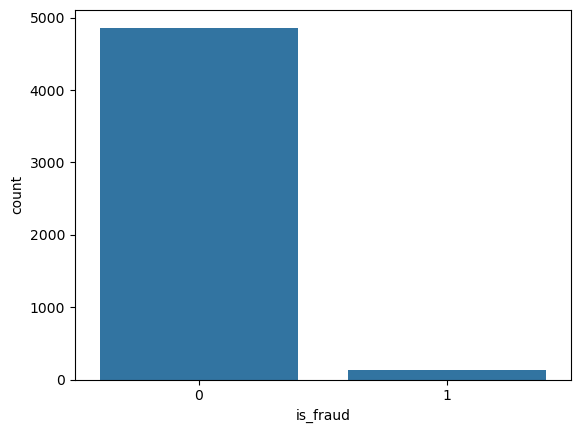

          Nombre  Pourcentage(%)
is_fraud                        
0           4864           97.28
1            136            2.72


In [17]:
sns.countplot(x="is_fraud", data=df)
plt.show()
repartition= df['is_fraud'].value_counts()
proportion= df['is_fraud'].value_counts(normalize= True) * 100
df_repartition= pd.DataFrame({'Nombre': repartition , 'Pourcentage(%)': proportion}) 
print(df_repartition)

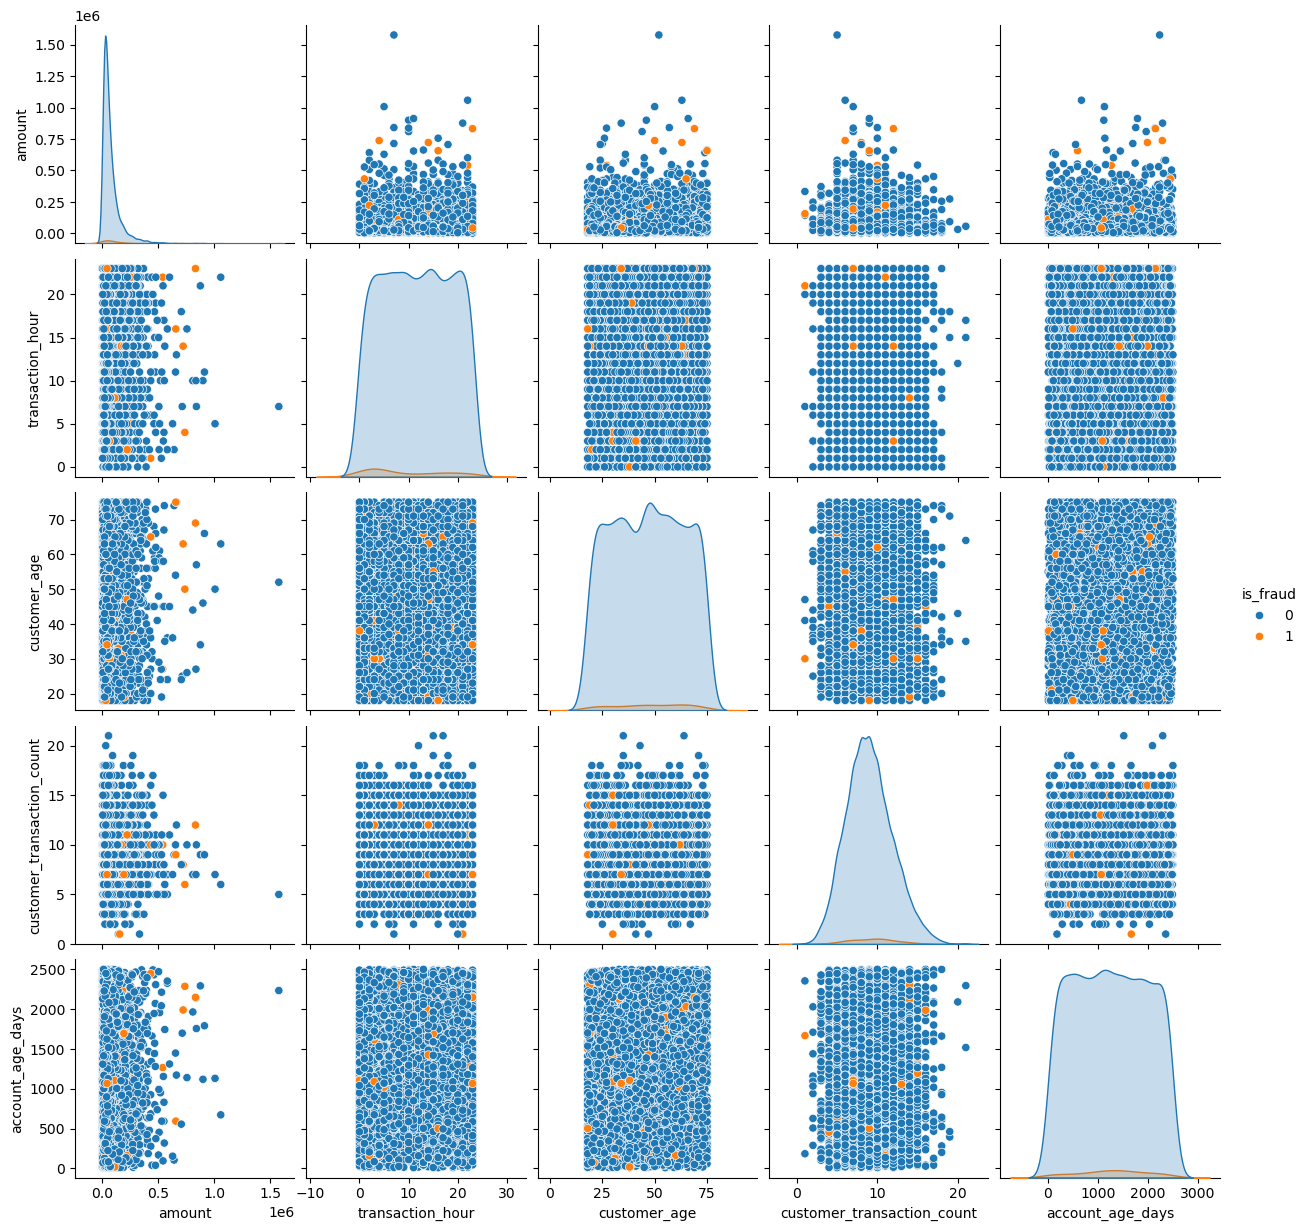

In [75]:
sns.pairplot(df,hue='is_fraud' ,vars=['amount','transaction_hour','customer_age','customer_transaction_count','account_age_days'])
plt.show()

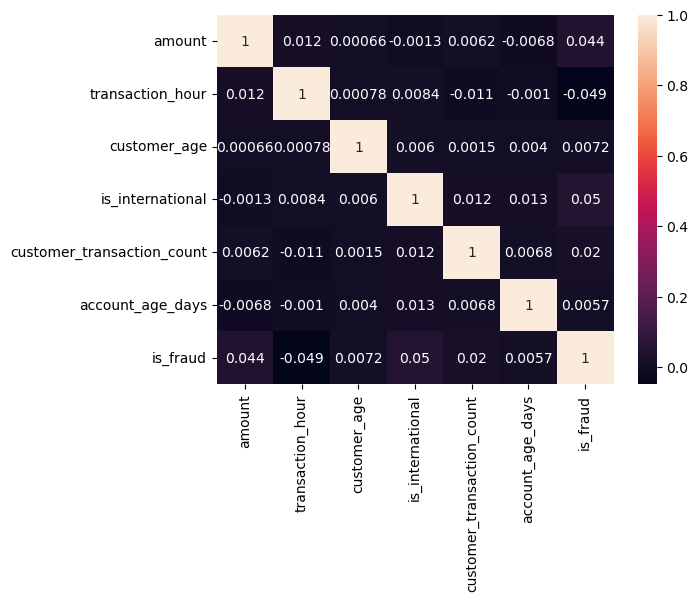

In [26]:
sns.heatmap(df.select_dtypes("number").corr(), annot=True)
plt.show()

In [18]:
#phase de préparation des données

df = pd.get_dummies(df, columns=["merchant_category","customer_country","payment_method"], drop_first = True)

In [19]:
X= df.drop(['is_fraud','transaction_id'], axis=1)
y= df['is_fraud']
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test= train_test_split(X,y, random_state=15, stratify=y, test_size=0.2)     

In [9]:
df.head()

,transaction_id,amount,transaction_hour,customer_age,is_international,customer_transaction_count,account_age_days,is_fraud,merchant_category_fashion,merchant_category_gaming,...,merchant_category_utilities,customer_country_Côte d'Ivoire,customer_country_France,customer_country_Ghana,customer_country_Nigeria,customer_country_Sénégal,customer_country_Togo,payment_method_card,payment_method_mobile_money,payment_method_wallet
0,TX100000,124800,21,31.0,0,6,839,0,False,False,...,False,False,False,False,True,False,False,False,True,False
1,TX100001,20500,17,38.0,0,5,365,0,False,False,...,False,True,False,False,False,False,False,False,False,False
2,TX100002,10700,9,67.0,0,10,922,0,True,False,...,False,False,True,False,False,False,False,True,False,False
3,TX100003,134700,1,23.0,1,11,1276,0,False,False,...,False,False,False,False,False,True,False,False,True,False
4,TX100004,111200,3,24.0,0,16,2206,0,False,False,...,False,True,False,False,False,False,False,False,True,False


[[ 70 903]
 [  3  24]]
              precision    recall  f1-score   support

      Normal       0.96      0.07      0.13       973
      Fraude       0.03      0.89      0.05        27

    accuracy                           0.09      1000
   macro avg       0.49      0.48      0.09      1000
weighted avg       0.93      0.09      0.13      1000



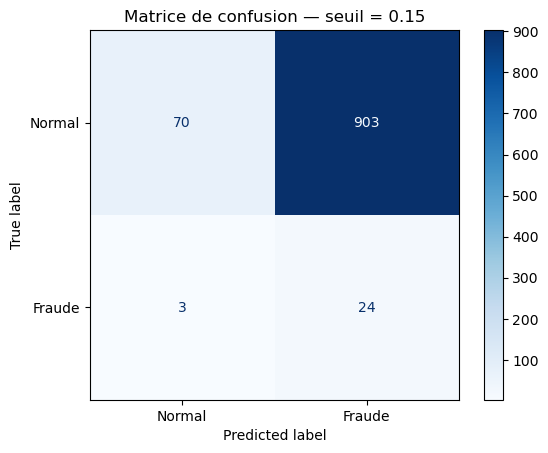

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    recall_score, precision_score,
    accuracy_score, f1_score,
    confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

# Standardisation
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Modèle
m_logistic = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

m_logistic.fit(X_train_scaled, y_train)

# Probabilités prédites par la régression logistique
seuil_choisi = 0.15

y_proba_l = m_logistic.predict_proba(X_test_scaled)[:, 1]

# Application du seuil
y_pred = (y_proba_l >= seuil_choisi).astype(int)

# Évaluation
print(confusion_matrix(y_test, y_pred))

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Normal", "Fraude"]
    )
)

# Matrice de confusion
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Normal", "Fraude"],
    cmap="Blues"
)

plt.title(f"Matrice de confusion — seuil = {seuil_choisi}")
plt.show()

In [49]:
df_resultats.head()

,seuil,recall,precision,accuracy,f1
0,0.05,1.000000,0.027000,0.027,0.052580
1,0.06,1.000000,0.027054,0.029,0.052683
2,0.07,1.000000,0.027190,0.034,0.052941
3,0.08,0.962963,0.026369,0.039,0.051333
4,0.09,0.962963,0.026585,0.047,0.051741


{'class_weight': {0: 1, 1: 30}, 'max_depth': 6, 'min_samples_leaf': 10, 'n_estimators': 200}
F1 (validation croisée) : 0.0968227565366279
[[ 70 903]
 [  3  24]]
              precision    recall  f1-score   support

      Normal       0.96      0.07      0.13       973
      Fraude       0.03      0.89      0.05        27

    accuracy                           0.09      1000
   macro avg       0.49      0.48      0.09      1000
weighted avg       0.93      0.09      0.13      1000



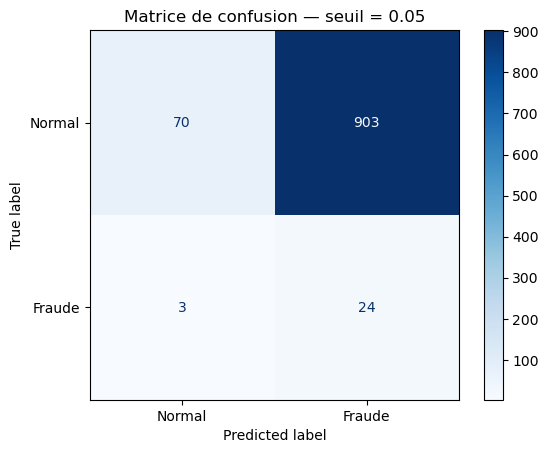

In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay, fbeta_score,make_scorer

# param_grid = {
#     'class_weight': [{0: 1, 1: w} for w in [1, 5, 10, 20, 30]],
#     'n_estimators': [100, 200, 300],       # nombre d'arbres dans la forêt
#     'max_depth': [6, 10, 15,None],
#     'min_samples_leaf': [1, 5, 10]
# }

# f2_scorer = make_scorer(fbeta_score, beta=2)

# grid = GridSearchCV(
#     RandomForestClassifier(random_state=15),
#     param_grid,
#     scoring= f2_scorer,
#     cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
#     n_jobs=-1
# )

# grid.fit(X_train, y_train)   # PAS besoin de X_train_scaled — les arbres n'ont pas besoin de normalisation

m_rf = grid.best_estimator_
print(grid.best_params_)
print("F1 (validation croisée) :", grid.best_score_)

m_rf.fit(X_train,y_train)
seuil_choisi_rf = 0.05
y_proba_rf = m_rf.predict_proba(X_test)[:, 1]
y_pred_rf = (y_proba_l >= seuil_choisi).astype(int)

# resultats_rt= []
# for k in np.arange(0.05, 0.19, 0.01):
#     y_pred_k = (y_proba_rf >= k).astype(int)
#     resultats_rt.append({
#         'seuil': round(k, 2),
#         'recall': recall_score(y_test, y_pred_k),
#         'precision': precision_score(y_test, y_pred_k, zero_division=0),
#         'accuracy': accuracy_score(y_test, y_pred_k),
#         'f1': f1_score(y_test, y_pred_k, zero_division=0)
#     })

# df_resultats_rf = pd.DataFrame(resultats_rt)
# df_resultats_rf.set_index('seuil').T.round(3)


print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf, target_names=["Normal", "Fraude"]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, display_labels=["Normal", "Fraude"], cmap="Blues")
plt.title(f"Matrice de confusion — seuil = {seuil_choisi_rf}")
plt.show()

In [86]:
print(m_rf)

RandomForestClassifier(class_weight={0: 1, 1: 30}, max_depth=6,
                       min_samples_leaf=10, n_estimators=200, random_state=15)


In [63]:
df_resultats_rf.head()

,seuil,recall,precision,accuracy,f1
0,0.05,1.0,0.027,0.027,0.05258
1,0.06,1.0,0.027,0.027,0.05258
2,0.07,1.0,0.027,0.027,0.05258
3,0.08,1.0,0.027,0.027,0.05258
4,0.09,1.0,0.027,0.027,0.05258


def predire_transaction(
    transaction_dict,
    modele,
    colonnes_attendues,
    scaler=None,
    seuil=0.15
):
    # 1. Dictionnaire → DataFrame
    df_transaction = pd.DataFrame([transaction_dict])

    # 2. Ajouter les colonnes manquantes
    for col in colonnes_attendues:
        if col not in df_transaction.columns:
            df_transaction[col] = 0

    # 3. Même ordre que pendant l'entraînement
    df_transaction = df_transaction[colonnes_attendues]

    # 4. Scaling si nécessaire
    if scaler is not None:
        df_transaction = scaler.transform(df_transaction)

    # 5. Probabilité de fraude
    proba_fraude = modele.predict_proba(df_transaction)[0, 1]

    # 6. Appliquer le seuil
    prediction = (
        "FRAUDE PROBABLE"
        if proba_fraude >= seuil
        else "TRANSACTION NORMALE"
    )

    print(f"Résultat : {prediction}")
    print(f"Probabilité de fraude : {proba_fraude * 100:.1f} %")

    return prediction, proba_fraude


# Utilisation
transaction = {
    "amount": 750000,
    "transaction_hour": 2,
    "customer_age": 23,
    "is_international": 1,
    "customer_transaction_count": 1,
    "account_age_days": 20
}

predire_transaction(transaction, m_rf, X_train.columns.tolist())

In [1]:
pip uninstall shap

^C
Note: you may need to restart the kernel to use updated packages.


In [32]:
import shap
explainer = shap.Explainer(m_rf)
shap_values = explainer.shape_values(X_test)
shap.plots.beeswarm(shap_values)

C extension was not built during install!


TypeError: The passed model is not callable and cannot be analyzed directly with the given masker! Model: RandomForestClassifier(class_weight={0: 1, 1: 30}, max_depth=6,
                       min_samples_leaf=10, n_estimators=200, random_state=15)